In [1]:
import io
import math
import numpy as np
import pandas as pd
import os
import cv2
from PIL import Image
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
import geopandas as gpd
from shapely.geometry import box
from tensorflow.keras.models import load_model
USE_COLAB = False
if USE_COLAB:
    from google.colab import drive
    drive.mount("/content/drive", force_remount=True)
    local_path = "/content/drive/MyDrive"
else:
    local_path = os.getcwd()

I0000 00:00:1793892695.786806   15556 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


I0000 00:00:1793892696.784125   15556 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


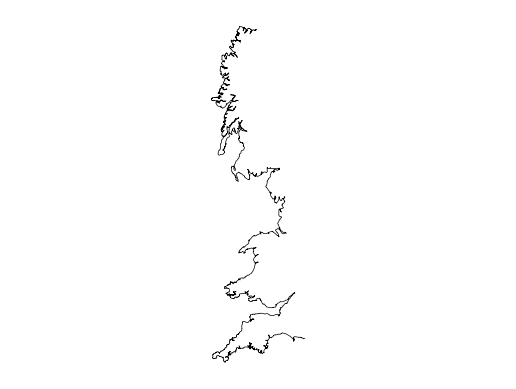

In [2]:
# Upload shapefile downloaded from GADM

gadm = gpd.read_file(f"{local_path}/../MAPPA/0/gadm41_GBR_0.shp")

# Explode MultiPolygon
gadm_exploded = gadm.explode(index_parts=False)

# Proietta in CRS metrico (UTM zone 50N, adatto per la Cina orientale)
gadm_proj = gadm_exploded.to_crs(epsg=32650)

# Calculate the area
gadm_proj["area"] = gadm_proj.geometry.area

# Filter out the polygon with lower area, so only the mainland remains

soglia_area = 100e9
gadm_filtered_proj = gadm_proj[gadm_proj["area"] > soglia_area]

gadm_filtered = gadm_filtered_proj.to_crs(epsg=4326)

# Select only a box
bbox = box(-8, 49.8, -2, 59)

# Reproject both the GADM layer and the bounding box into a metric coordinate system.

gadm_proj = gadm_filtered.to_crs("EPSG:32630")
bbox_proj = gpd.GeoSeries([bbox], crs="EPSG:4326").to_crs("EPSG:32630").iloc[0]

clipped = gadm_proj.clip(bbox_proj)
geom = clipped.geometry.iloc[0]

%matplotlib inline

geom = clipped.geometry.iloc[0]

if geom.geom_type == "MultiPolygon":
    geom = list(geom.geoms)[0]

# Remove the straight line

coords = list(geom.exterior.coords)

max_index = max(range(len(coords)), key=lambda i: coords[i][0])

coords = coords[max_index:] + coords[:max_index]

# Select the portion of coastline

start, end = 0, 730000
subset = coords[start:end]

x, y = zip(*subset)

plt.plot(x, y, color="black", linewidth = 0.5)
plt.gca().set_aspect('equal', adjustable='datalim')
plt.axis("equal")
plt.axis('off')

plt.show()

In [3]:
matplotlib.use("Agg")

def rasterize_segments(segments, img_size=(515, 389)):
    '''
    Given the coordinates, it creates a binary image of specific dimensions.
    '''

    fig, ax = plt.subplots(figsize=(img_size[0]/100, img_size[1]/100), dpi=100)
    ax.set_axis_off()
    ax.set_aspect('equal', adjustable='box')

    all_coords = np.vstack(segments)
    min_x, max_x = all_coords[:, 0].min(), all_coords[:, 0].max()
    min_y, max_y = all_coords[:, 1].min(), all_coords[:, 1].max()

    ax.set_xlim(min_x, max_x)
    ax.set_ylim(min_y, max_y)

    for seg in segments:
        if len(seg) > 1:
            ax.plot(seg[:,0], seg[:,1], color='black', linewidth=1)

    plt.subplots_adjust(left=0, right=1, top=1, bottom=0)

    fig.canvas.draw()

    img_rgba = np.array(fig.canvas.renderer.buffer_rgba())
    plt.close(fig)

    img = Image.fromarray(img_rgba).convert("L")
    img = img.resize(img_size, Image.LANCZOS)
    img = img.point(lambda p: 255 if p > 128 else 0)

    return np.array(img)

In [4]:
def Image_Loader_fractal(dataframe, range_0, range_length):
   '''
   This function gives as output the set of images that will be evaluated and their respective fractal dimension (label) as np arrays.
   It is specific for the box counting.
   '''
   eval_set = []

   for i in range(range_0,range_length):

      coords = dataframe[i]

      threshold = 200

      img = rasterize_segments([coords], img_size=(515, 389))

      img1 = np.array(img)
      image = (img1 > threshold).astype(np.float32)
      eval_set.append(image)

   eval_set = np.asarray(eval_set)
   return eval_set

In [5]:
def Image_Loader(dataframe, range_0, range_length):
   '''
   This function gives as output the set of images that will be evaluated and their respective fractal dimension (label) as np arrays
   '''

   eval_set = []

   for i in range(range_0,range_length):

      coords = dataframe[i]

      threshold = 200

      img = rasterize_segments([coords], img_size=(515, 389))

      img1 = np.array(img)
      img2 = (img1 > threshold).astype(np.float32)

      image = img2[:, :, np.newaxis]
      eval_set.append(image)

   eval_set = np.asarray(eval_set)
   return eval_set

In [6]:
def boxcount(Z, k):
    '''
    Given the dimension of the box k, and the matrix Z, it returns the number of
    boxes, used to cover the matrix, with at least a 1 inside.
    '''
    rows, cols = Z.shape
    n_rows = rows // k
    n_cols = cols // k

    count = 0
    for i in range(n_rows):
        for j in range(n_cols):
            block = Z[i*k:(i+1)*k, j*k:(j+1)*k]
            if np.any(block):
                count += 1
    return count

def fractal_dimension(image):
    """
    Given an image, it converts it into a binary matrix with values 0 and 1.
    Using this binary representation, it applies the box‑counting method:
    for multiple grid sizes, it counts how many boxes contain part of the curve.

    The fractal dimension is estimated as the slope of the linear regression
    between log(box count) and log(box size).
    """

    img = np.array(image)

    binary = (img == 0).astype(np.uint8)

    sizes = [2, 4, 8, 16, 32, 64]
    counts = [boxcount(binary, k) for k in sizes]

    log_sizes = np.log(sizes)
    log_counts = np.log(counts)

    coeffs = np.polyfit(log_sizes, log_counts, 1)
    fractal_dim = -coeffs[0]

    fit_line = coeffs[0] * log_sizes + coeffs[1]

    return fractal_dim

Divide the coastline in 73 portions of **equal length along the coastline** (instead of an equal number of points).

The cumulative arc length is computed along the polyline, and the segment boundaries are placed at multiples of L/N.

In [7]:
def split_by_length(points, N):
    '''
    Split a polyline into N consecutive pieces with the same length along the curve.
    Returns the list of pieces and the index boundaries (so that piece i is points[b[i]:b[i+1]]).
    '''
    points = np.asarray(points)
    step = np.linalg.norm(np.diff(points, axis=0), axis=1)
    s = np.concatenate([[0], np.cumsum(step)])          # cumulative arc length (m)
    targets = np.linspace(0, s[-1], N + 1)
    bounds = np.searchsorted(s, targets)
    bounds[0], bounds[-1] = 0, len(points)
    pieces = [points[bounds[i]:bounds[i+1]] for i in range(N)]
    return pieces, bounds

test = np.array(subset)

N = 73
test_df, bounds1 = split_by_length(test, N)

seg_len_km = [np.linalg.norm(np.diff(p, axis=0), axis=1).sum() / 1e3 for p in test_df]
print(f"{N} segments, length {np.mean(seg_len_km):.1f} km each "
      f"(min {np.min(seg_len_km):.1f}, max {np.max(seg_len_km):.1f}); "
      f"points per segment: {min(map(len, test_df))}-{max(map(len, test_df))}")

73 segments, length 107.2 km each (min 106.5, max 107.3); points per segment: 5224-13553


In [8]:
ms = f'{local_path}/../Model/MainModel/AlexNet_model.keras'
model = load_model(ms)

In [9]:
# evaluate the value with the CNN

test_image_set= Image_Loader(test_df, 0, len(test_df))

Basins_Characterized_df = model.predict(test_image_set)

predicted_values = Basins_Characterized_df.flatten()

1/3 ━━━━━━━━━━━━━━━━━━━━ 4s 2s/step

2/3 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step

3/3 ━━━━━━━━━━━━━━━━━━━━ 5s 1s/step


In [10]:
# evaluate the values with the box counting

D = []
test_image_set= Image_Loader_fractal(test_df, 0, len(test_df))
for i in test_image_set:
  dimfrattale = fractal_dimension(i)
  D.append(dimfrattale)

In [11]:
# Put everything togheter in a dataframe

D = np.array(D)

result_df = pd.DataFrame({
    'CNN': predicted_values,
    'Box' : D
})
print(result_df[['CNN', 'Box']])

         CNN       Box
0   1.065630  1.096596
1   1.051111  1.069515
2   1.253010  1.215638
3   1.270877  1.182580
4   1.260800  1.196265
..       ...       ...
68  1.262114  1.275487
69  1.320224  1.332394
70  1.227601  1.212727
71  1.171371  1.180242
72  1.186906  1.183159

[73 rows x 2 columns]


Divide the coastline in 13 portions of equal length along the coastline.

In [12]:
test2 = np.array(subset)

N2 = 13
test_df2, bounds2 = split_by_length(test2, N2)

seg_len_km2 = [np.linalg.norm(np.diff(p, axis=0), axis=1).sum() / 1e3 for p in test_df2]
print(f"{N2} segments, length {np.mean(seg_len_km2):.1f} km each "
      f"(min {np.min(seg_len_km2):.1f}, max {np.max(seg_len_km2):.1f}); "
      f"points per segment: {min(map(len, test_df2))}-{max(map(len, test_df2))}")

13 segments, length 602.5 km each (min 602.3, max 602.5); points per segment: 47486-68168


In [13]:
# evaluate the value with the CNN

test_image_set2= Image_Loader(test_df2, 0, len(test_df2))

Basins_Characterized_df2 = model.predict(test_image_set2)

predicted_values2 = Basins_Characterized_df2.flatten()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step


In [14]:
# evaluate the values with the box counting

D2 = []
test_image_set2= Image_Loader_fractal(test_df2, 0, len(test_df2))
for i in test_image_set2:
  dimfrattale = fractal_dimension(i)
  D2.append(dimfrattale)

In [15]:
# Put everything togheter in a dataframe

D2 = np.array(D2)

result_df2 = pd.DataFrame({
    'CNN': predicted_values2,
    'Box' : D2
})
print(result_df2[['CNN', 'Box']])

         CNN       Box
0   1.232826  1.185825
1   1.210966  1.181577
2   1.120537  1.163188
3   1.286164  1.200596
4   1.153976  1.140873
5   1.144744  1.219809
6   1.211539  1.187259
7   1.215532  1.231214
8   1.303189  1.238325
9   1.353372  1.273845
10  1.348227  1.269594
11  1.270803  1.255834
12  1.320792  1.245323


In [16]:
# Select the extreme for the color scale

vmin1=min(result_df['CNN'].min(), result_df2['CNN'].min())
vmax1=max(result_df['CNN'].max(), result_df2['CNN'].max())
vmin2=min(result_df['Box'].min(), result_df2['Box'].min())
vmax2=max(result_df['Box'].max(), result_df2['Box'].max())

Represent the coastline with a color scale based on the fractal dimension.

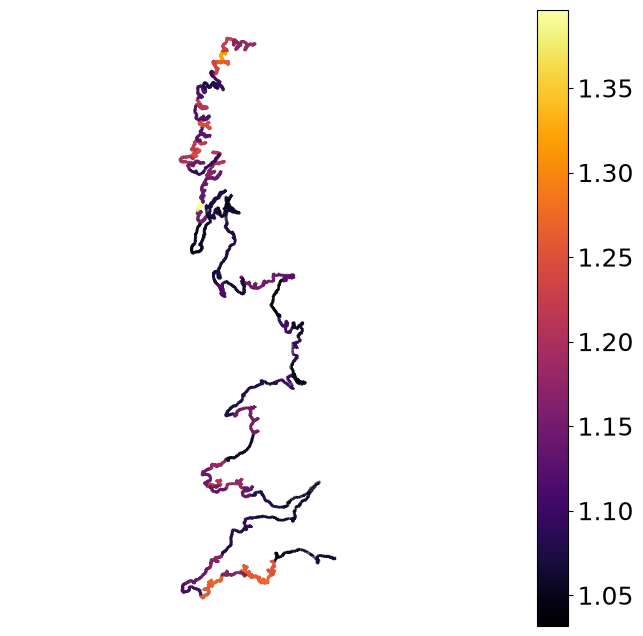

In [17]:
%matplotlib inline


fig, ax = plt.subplots(figsize=(8,8))

norm = plt.Normalize(vmin=np.min([vmin1, vmin2]), vmax=np.max([vmax1, vmax2]))
cmap = plt.cm.inferno

for i in range(N):
    start = bounds1[i]
    end = bounds1[i+1]

    r, t = x[start:end], y[start:end]

    c = result_df['CNN'].iloc[i]

    points = np.array([r, t]).T.reshape(-1, 1, 2)
    segments = np.concatenate([points[:-1], points[1:]], axis=1)

    lc = LineCollection(segments, cmap=cmap, norm=norm, linewidth=2)
    lc.set_array(np.full(len(segments), c))

    ax.add_collection(lc)

ax.autoscale()
ax.axis("off")
ax.set_aspect('equal', adjustable='datalim')

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
cbar = fig.colorbar(sm, ax=ax)
cbar.ax.tick_params(labelsize=18)
sm.set_array([])

plt.show()

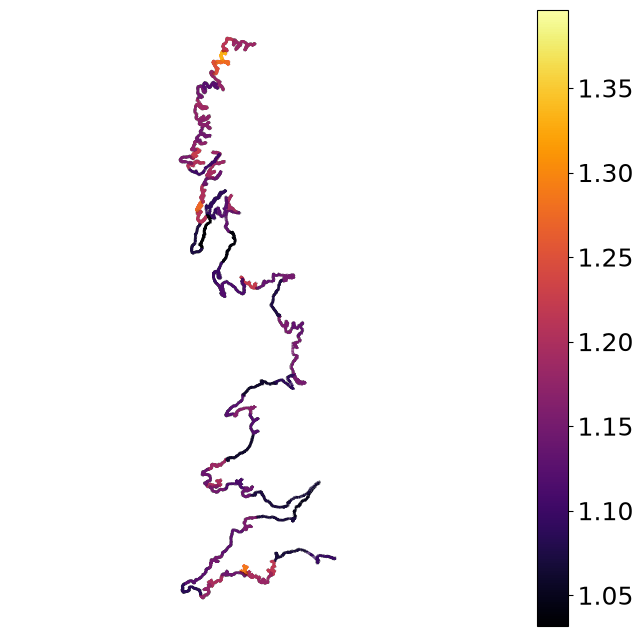

In [18]:
%matplotlib inline


fig, ax = plt.subplots(figsize=(8,8))

norm = plt.Normalize(vmin=np.min([vmin1, vmin2]), vmax=np.max([vmax1, vmax2]))
cmap = plt.cm.inferno

for i in range(N):
    start = bounds1[i]
    end = bounds1[i+1]

    r, t = x[start:end], y[start:end]

    c = result_df['Box'].iloc[i]

    points = np.array([r, t]).T.reshape(-1, 1, 2)
    segments = np.concatenate([points[:-1], points[1:]], axis=1)

    lc = LineCollection(segments, cmap=cmap, norm=norm, linewidth=2)
    lc.set_array(np.full(len(segments), c))

    ax.add_collection(lc)

ax.autoscale()
ax.axis("off")
ax.set_aspect('equal', adjustable='datalim')

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax)
cbar.ax.tick_params(labelsize=18)

plt.show()

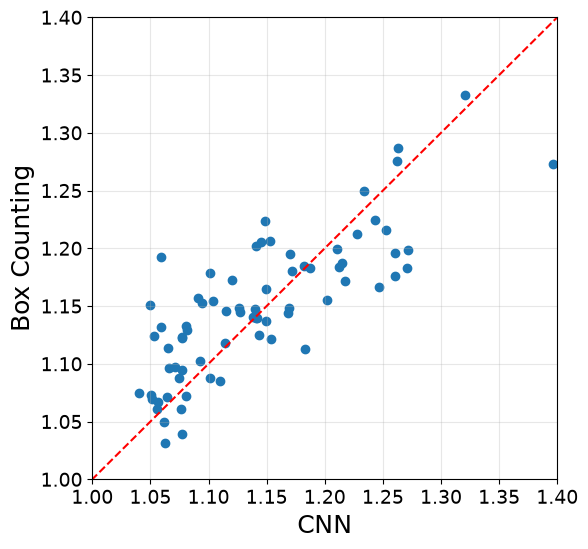

In [19]:
plt.figure(figsize=(6, 6))
plt.scatter(result_df['CNN'], result_df['Box'])
plt.xlabel('CNN', fontsize=18)
plt.ylabel('Box Counting', fontsize=18)
plt.xlim(1, 1.4)
plt.ylim(1, 1.4)

plt.xticks(fontsize=14)
plt.yticks(fontsize=14)


plt.plot([0.9, 1.5], [0.9, 1.5], 'r--')
plt.grid(True, alpha=0.3)

plt.show()

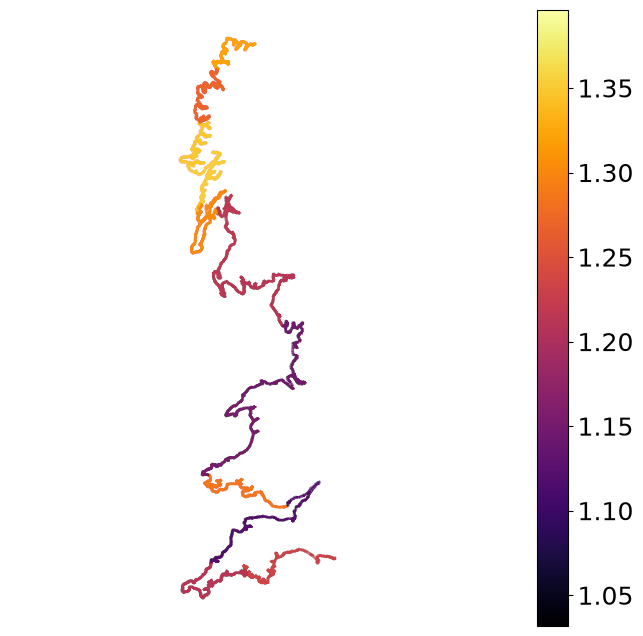

In [20]:
%matplotlib inline


fig, ax = plt.subplots(figsize=(8,8))

norm = plt.Normalize(vmin=np.min([vmin1, vmin2]), vmax=np.max([vmax1, vmax2]))
cmap = plt.cm.inferno

for i in range(N2):
    start = bounds2[i]
    end = bounds2[i+1]

    r, t = x[start:end], y[start:end]

    c = result_df2['CNN'].iloc[i]

    points = np.array([r, t]).T.reshape(-1, 1, 2)
    segments = np.concatenate([points[:-1], points[1:]], axis=1)

    lc = LineCollection(segments, cmap=cmap, norm=norm, linewidth=2)
    lc.set_array(np.full(len(segments), c))

    ax.add_collection(lc)

ax.autoscale()
ax.axis("off")
ax.set_aspect('equal', adjustable='datalim')

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
cbar = fig.colorbar(sm, ax=ax)
cbar.ax.tick_params(labelsize=18)
sm.set_array([])

plt.show()

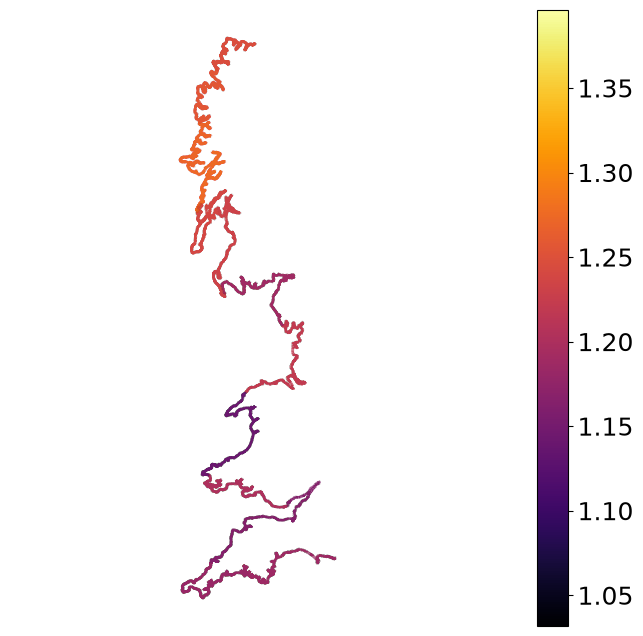

In [21]:
%matplotlib inline


fig, ax = plt.subplots(figsize=(8,8))

norm = plt.Normalize(vmin=np.min([vmin1, vmin2]), vmax=np.max([vmax1, vmax2]))
cmap = plt.cm.inferno

for i in range(N2):
    start = bounds2[i]
    end = bounds2[i+1]

    r, t = x[start:end], y[start:end]

    c = result_df2['Box'].iloc[i]

    points = np.array([r, t]).T.reshape(-1, 1, 2)
    segments = np.concatenate([points[:-1], points[1:]], axis=1)

    lc = LineCollection(segments, cmap=cmap, norm=norm, linewidth=2)
    lc.set_array(np.full(len(segments), c))

    ax.add_collection(lc)

ax.autoscale()
ax.axis("off")
ax.set_aspect('equal', adjustable='datalim')

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax)
cbar.ax.tick_params(labelsize=18)

plt.show()

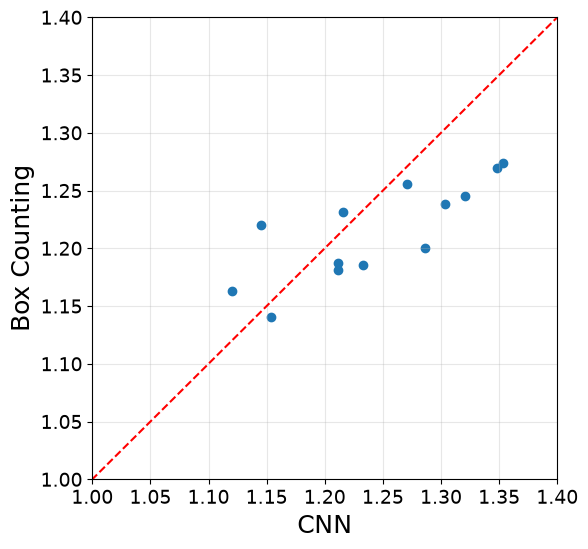

In [22]:
plt.figure(figsize=(6, 6))
plt.scatter(result_df2['CNN'], result_df2['Box'])
plt.xlabel('CNN', fontsize=18)
plt.ylabel('Box Counting', fontsize=18)
plt.xlim(1, 1.4)
plt.ylim(1, 1.4)

plt.xticks(fontsize=14)
plt.yticks(fontsize=14)


plt.plot([0.9, 1.5], [0.9, 1.5], 'r--')
plt.grid(True, alpha=0.3)

plt.show()

## Fractal dimension vs segment length

If the coastline were exactly self-similar, the fractal dimension would not depend on how long the segments are.
Here the same coastline is split into N equal-length segments for several N, and D is estimated for each segment with both the CNN and box counting.
Each segment is drawn into the same 515×389 image, so longer segments are looked at at coarser resolution (more metres per pixel).
A flat curve would mean D is the same at every scale; a curve that rises with segment length means D depends on scale.

In [23]:
N_list = [5, 13, 25, 50, 100, 200]

import gc
chunk = 20

scan = []
for Nk in N_list:
    pieces, _ = split_by_length(subset, Nk)
    L_km = np.linalg.norm(np.diff(np.asarray(subset), axis=0), axis=1).sum() / 1e3 / Nk

    # process in small chunks to keep memory low (AlexNet activations are large)
    cnn_k, box_k = [], []
    for j in range(0, Nk, chunk):
        jend = min(j + chunk, Nk)
        imgs = Image_Loader(pieces, j, jend)
        cnn_k.append(model.predict(imgs, batch_size=4, verbose=0).flatten())
        box_k += [fractal_dimension(im[:, :, 0]) for im in imgs]
        del imgs; gc.collect()
    cnn_k, box_k = np.concatenate(cnn_k), np.array(box_k)

    span_km = np.mean([max(np.ptp(q[:, 0]), np.ptp(q[:, 1])) for q in pieces]) / 1e3
    scan.append(dict(N=Nk, length_km=L_km, span_km=span_km, m_per_px=span_km * 1e3 / 515,
                     CNN_mean=cnn_k.mean(), CNN_std=cnn_k.std(),
                     Box_mean=box_k.mean(), Box_std=box_k.std(),
                     CNN_all=cnn_k, Box_all=box_k))
    print(f"N={Nk:4d}  length={L_km:7.1f} km  CNN={cnn_k.mean():.3f}±{cnn_k.std():.3f}  Box={box_k.mean():.3f}±{box_k.std():.3f}")

scan_df = pd.DataFrame(scan)
print(scan_df[['N', 'length_km', 'span_km', 'm_per_px', 'CNN_mean', 'CNN_std', 'Box_mean', 'Box_std']].round(3))

N=   5  length= 1566.6 km  CNN=1.318±0.062  Box=1.235±0.079


N=  13  length=  602.5 km  CNN=1.244±0.074  Box=1.215±0.040


N=  25  length=  313.3 km  CNN=1.202±0.079  Box=1.186±0.059


N=  50  length=  156.7 km  CNN=1.158±0.079  Box=1.162±0.060


N= 100  length=   78.3 km  CNN=1.126±0.070  Box=1.137±0.047


N= 200  length=   39.2 km  CNN=1.094±0.059  Box=1.119±0.046
     N  length_km  span_km  m_per_px  CNN_mean  CNN_std  Box_mean  Box_std
0    5   1566.551  243.599   473.008     1.318    0.062     1.235    0.079
1   13    602.520  124.548   241.841     1.244    0.074     1.215    0.040
2   25    313.310   74.098   143.880     1.202    0.079     1.186    0.059
3   50    156.655   45.542    88.431     1.158    0.079     1.162    0.060
4  100     78.328   26.579    51.609     1.126    0.070     1.137    0.047
5  200     39.164   15.783    30.647     1.094    0.059     1.119    0.046


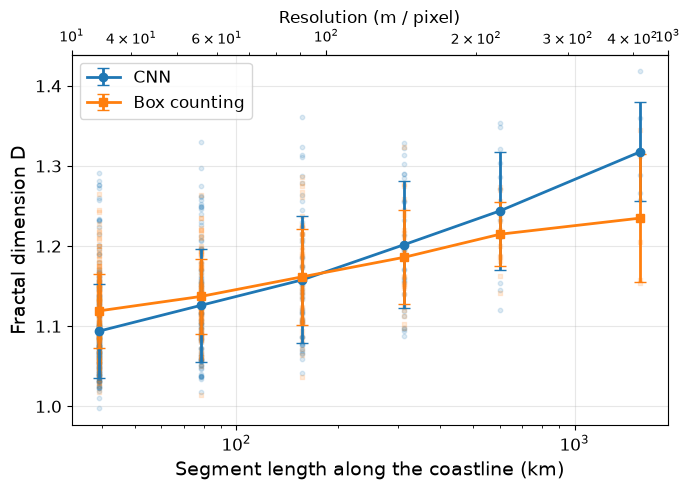

In [24]:
fig, ax = plt.subplots(figsize=(7, 5))

for key, col, mk in [('CNN', 'tab:blue', 'o'), ('Box', 'tab:orange', 's')]:
    for _, row in scan_df.iterrows():
        ax.scatter(np.full(len(row[f'{key}_all']), row['length_km']), row[f'{key}_all'],
                   color=col, alpha=0.15, s=10, marker=mk)
    ax.errorbar(scan_df['length_km'], scan_df[f'{key}_mean'], yerr=scan_df[f'{key}_std'],
                color=col, marker=mk, capsize=4, lw=2, label=key if key == 'CNN' else 'Box counting')

ax.set_xscale('log')
ax.set_xlabel('Segment length along the coastline (km)', fontsize=14)
ax.set_ylabel('Fractal dimension D', fontsize=14)
ax.tick_params(labelsize=12)
ax.grid(True, alpha=0.3)
ax.legend(fontsize=12)

secax = ax.secondary_xaxis('top', functions=(
    lambda L: np.interp(L, scan_df['length_km'][::-1], scan_df['m_per_px'][::-1]),
    lambda m: np.interp(m, scan_df['m_per_px'][::-1], scan_df['length_km'][::-1])))
secax.set_xlabel('Resolution (m / pixel)', fontsize=12)

plt.tight_layout()
plt.show()

Coastline coloured by D for each N: CNN on the top row, box counting on the bottom row. All panels share the same colour scale.

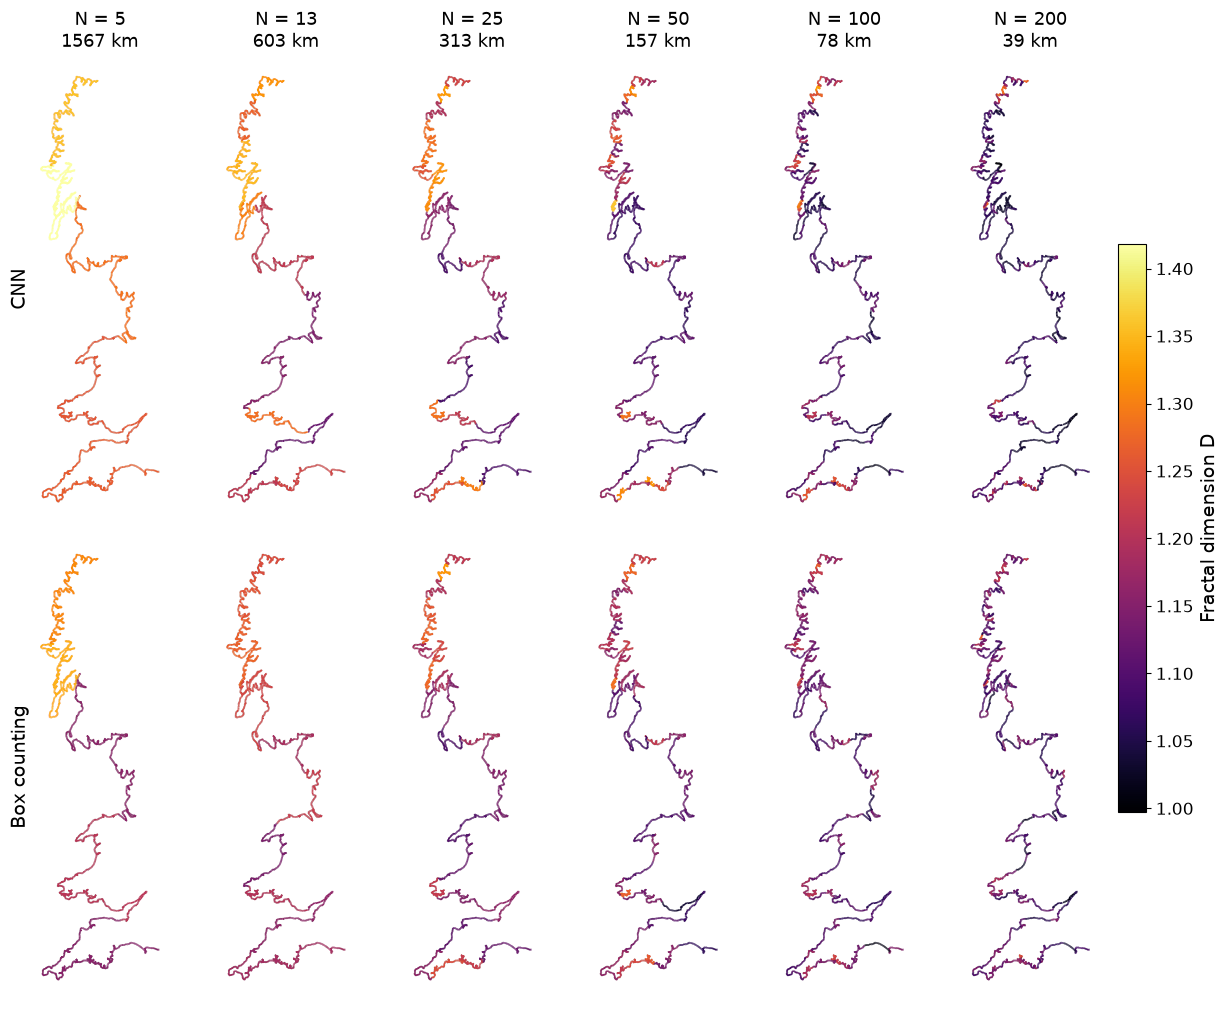

In [25]:
%matplotlib inline

plot_step = 10   # draw every 10th point (visual only, the D values are those computed above)
pts = np.asarray(subset)

all_D = np.concatenate([np.concatenate(scan_df['CNN_all']), np.concatenate(scan_df['Box_all'])])
norm = plt.Normalize(vmin=all_D.min(), vmax=all_D.max())
cmap = plt.cm.inferno

nN = len(scan_df)
fig, axes = plt.subplots(2, nN, figsize=(1.9 * nN + 1, 10), constrained_layout=True)

for col, (_, row) in enumerate(scan_df.iterrows()):
    _, b = split_by_length(pts, int(row['N']))
    for r_i, key in enumerate(['CNN', 'Box']):
        ax = axes[r_i, col]
        for i in range(int(row['N'])):
            seg = pts[b[i]:b[i+1] + 1:plot_step]   # +1 so neighbouring segments touch
            if len(seg) < 2:
                seg = pts[b[i]:b[i+1] + 1]
            p2 = seg.reshape(-1, 1, 2)
            lc = LineCollection(np.concatenate([p2[:-1], p2[1:]], axis=1),
                                cmap=cmap, norm=norm, linewidth=1.2)
            lc.set_array(np.full(len(p2) - 1, row[f'{key}_all'][i]))
            ax.add_collection(lc)
        ax.autoscale()
        ax.set_aspect('equal', adjustable='box')
        ax.set_xticks([]); ax.set_yticks([])
        for s in ax.spines.values():
            s.set_visible(False)
        if r_i == 0:
            ax.set_title(f"N = {int(row['N'])}\n{row['length_km']:.0f} km", fontsize=13)
        if col == 0:
            ax.set_ylabel('CNN' if key == 'CNN' else 'Box counting', fontsize=14)

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, ax=axes, shrink=0.6, pad=0.02)
cbar.set_label('Fractal dimension D', fontsize=14)
cbar.ax.tick_params(labelsize=12)

plt.show()